# GPU-Based Machine Learning Application: CNN Image Classification

## Objective

To implement and evaluate a Convolutional Neural Network (CNN) for image classification using GPU acceleration.

The experiment uses the CIFAR-10 dataset and PyTorch framework to demonstrate GPU-based model training and evaluate its computational performance.

The study includes:
- GPU environment verification.
- Dataset preparation.
- CNN model implementation.
- GPU-based model training.
- Model accuracy and loss evaluation.
- Training performance measurement.
- GPU resource utilization monitoring.

In [1]:
!nvidia-smi

Thu Nov 12 16:08:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
import time

print("NumPy version:", np.__version__)
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = torch.device("cuda")

    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
    print("Selected device:", device)
else:
    device = torch.device("cpu")
    print("GPU not available. Please select a GPU runtime.")

NumPy version: 2.4.6
PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0
Selected device: cuda


## 2. Dataset Preparation

The CIFAR-10 dataset is used for the image classification task.

It contains 60,000 colour images belonging to 10 different classes. Each image has a resolution of 32 × 32 pixels.

The dataset is divided into:
- 50,000 training images.
- 10,000 testing images.

The training dataset is used to train the CNN model, while the testing dataset is used to evaluate its classification performance.

In [3]:
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

# Convert images to PyTorch tensors
transform = transforms.ToTensor()

# Load training dataset
train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Load testing dataset
test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

class_names = train_dataset.classes

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Number of classes:", len(class_names))
print("Classes:", class_names)

100%|██████████| 170M/170M [22:55<00:00, 124kB/s]


Training images: 50000
Testing images: 10000
Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 3. CNN Model Implementation

A Convolutional Neural Network (CNN) is a deep learning model commonly used for image classification.

CNNs use convolutional layers to extract spatial features from images, pooling layers to reduce feature-map dimensions, and fully connected layers to perform classification.

In this experiment, a simple CNN is implemented using PyTorch.

The model consists of:
- Two convolutional layers with ReLU activation.
- Max-pooling layers for spatial dimension reduction.
- A fully connected hidden layer.
- An output layer with 10 neurons corresponding to the CIFAR-10 classes.

The model is transferred to the NVIDIA GPU for accelerated training.

In [5]:
import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


# Create model and transfer it to GPU
model = CNN().to(device)

print(model)
print("\nModel device:", next(model.parameters()).device)

print(
    "\nTotal trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

Model device: cuda:0

Total trainable parameters: 545098


## 4. Model Training Configuration

The CNN model is trained using the following configuration:

- Loss function: Cross-Entropy Loss.
- Optimizer: Adam.
- Learning rate: 0.001.
- Batch size: 128.
- Number of epochs: 5.

The model parameters are updated using backpropagation and gradient descent.

The training process is executed on the NVIDIA Tesla T4 GPU.

In [6]:
# Define loss function
criterion = nn.CrossEntropyLoss()

# Define optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Number of training epochs
num_epochs = 5

print("Training configuration:")
print("Device:", device)
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Batch size: 128")
print("Epochs:", num_epochs)

Training configuration:
Device: cuda
Optimizer: Adam
Learning rate: 0.001
Batch size: 128
Epochs: 5


## 5. GPU-Based Model Training

The CNN model is trained using the CIFAR-10 training dataset.

During each training iteration:

1. A batch of images is transferred to GPU memory.
2. The model performs forward propagation.
3. The loss is calculated using Cross-Entropy Loss.
4. Backpropagation computes gradients.
5. The Adam optimizer updates the model parameters.

The training process is executed on the NVIDIA Tesla T4 GPU.

Training loss and execution time are recorded for performance evaluation.

In [7]:
# Lists to store training results
train_losses = []
epoch_times = []

# Synchronize GPU before starting measurement
torch.cuda.synchronize()
training_start = time.time()

for epoch in range(num_epochs):

    model.train()
    running_loss = 0.0

    epoch_start = time.time()

    for images, labels in train_loader:

        # Transfer batch to GPU
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        running_loss += loss.item()

    # Synchronize GPU for accurate timing
    torch.cuda.synchronize()

    epoch_time = time.time() - epoch_start
    average_loss = running_loss / len(train_loader)

    train_losses.append(average_loss)
    epoch_times.append(epoch_time)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Loss: {average_loss:.4f} "
        f"Time: {epoch_time:.2f} seconds"
    )

torch.cuda.synchronize()
total_training_time = time.time() - training_start

print("\nTraining completed!")
print(f"Total GPU training time: {total_training_time:.2f} seconds")

Epoch [1/5] Loss: 1.5183 Time: 9.19 seconds
Epoch [2/5] Loss: 1.1691 Time: 6.51 seconds
Epoch [3/5] Loss: 1.0229 Time: 7.96 seconds
Epoch [4/5] Loss: 0.9244 Time: 7.51 seconds
Epoch [5/5] Loss: 0.8478 Time: 7.54 seconds

Training completed!
Total GPU training time: 38.71 seconds


## 6. Model Evaluation

After training, the CNN model is evaluated using the CIFAR-10 testing dataset.

The model predicts the class of each test image. Its predictions are compared with the actual labels to calculate classification accuracy.

The evaluation is performed without updating model parameters.

In [8]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print("Total test images:", total)
print("Correct predictions:", correct)
print(f"Test Accuracy: {test_accuracy:.2f}%")

Total test images: 10000
Correct predictions: 6687
Test Accuracy: 66.87%


## 7. Training Performance Visualization

The training loss and execution time are visualized to understand the learning behaviour and computational performance of the CNN model.

The plots show:
- Training loss across epochs.
- GPU training time for each epoch.

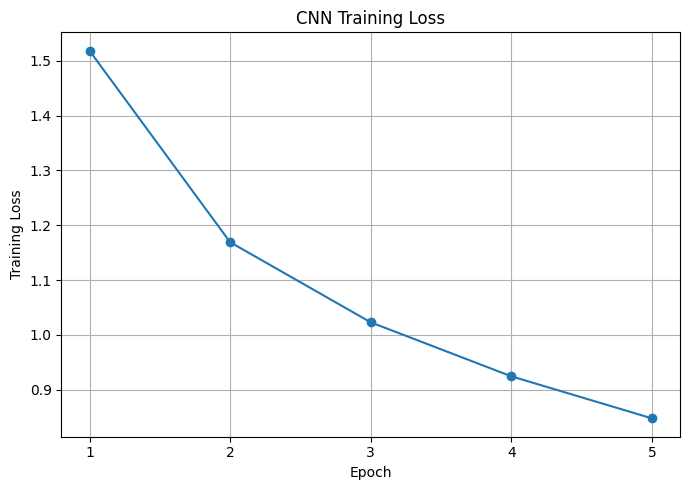

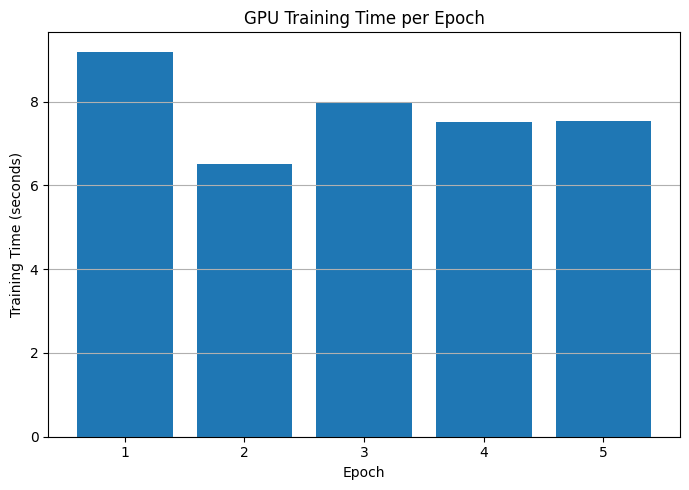

In [9]:
import os

# Create results directory
os.makedirs("results/figures", exist_ok=True)

epochs = range(1, num_epochs + 1)

# Plot training loss
plt.figure(figsize=(7, 5))
plt.plot(epochs, train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("CNN Training Loss")
plt.xticks(list(epochs))
plt.grid(True)
plt.tight_layout()
plt.savefig("results/figures/ml_training_loss.png", dpi=300)
plt.show()

# Plot epoch training time
plt.figure(figsize=(7, 5))
plt.bar(list(epochs), epoch_times)
plt.xlabel("Epoch")
plt.ylabel("Training Time (seconds)")
plt.title("GPU Training Time per Epoch")
plt.xticks(list(epochs))
plt.grid(axis="y")
plt.tight_layout()
plt.savefig("results/figures/ml_epoch_training_time.png", dpi=300)
plt.show()

In [11]:
training_results = pd.DataFrame({
    "Epoch": range(1, num_epochs + 1),
    "Training Loss": train_losses,
    "Training Time (seconds)": epoch_times
})

display(training_results.round(4))

evaluation_results = pd.DataFrame({
    "Metric": [
        "Total GPU Training Time (seconds)",
        "Final Training Loss",
        "Test Accuracy (%)",
        "Correct Predictions",
        "Total Test Images"
    ],
    "Value": [
        total_training_time,
        train_losses[-1],
        test_accuracy,
        correct,
        total
    ]
})

display(evaluation_results.round(4))

,Epoch,Training Loss,Training Time (seconds)
0,1,1.5183,9.1920
1,2,1.1691,6.5086
2,3,1.0229,7.9609
3,4,0.9244,7.5072
4,5,0.8478,7.5421


,Metric,Value
0,Total GPU Training Time (seconds),38.7127
1,Final Training Loss,0.8478
2,Test Accuracy (%),66.8700
3,Correct Predictions,6687.0000
4,Total Test Images,10000.0000


## Results and Discussion

The CNN model was trained on the CIFAR-10 dataset using the NVIDIA Tesla T4 GPU for five epochs.

The training loss decreased from 1.5183 in the first epoch to 0.8478 in the fifth epoch, indicating that the model learned from the training data.

The total GPU training time was approximately 38.71 seconds. During evaluation, the model achieved a test accuracy of 66.87%, correctly classifying 6,687 out of 10,000 test images.

These results demonstrate the execution of a deep learning workload using cloud GPU acceleration.

## Experimental Limitations

- The model was trained for only five epochs.
- A relatively simple CNN architecture was used.
- The experiment was conducted using the CIFAR-10 dataset.
- GPU utilization was not continuously monitored during the training process.
- The results may vary across different runtime sessions and hardware configurations.

## Conclusion

A CNN-based image classification workload was successfully implemented using PyTorch and executed on the Google Colab NVIDIA Tesla T4 GPU.

The experiment demonstrated GPU-accelerated model training and evaluation, with a total training time of approximately 38.71 seconds and a test accuracy of 66.87%.

This completes the ML application component of the project.